In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)


PyTorch version: 2.2.1+cu121
Device: cuda


In [2]:
%pip install -q kagglehub

import kagglehub
import os

path = kagglehub.dataset_download(
    "paultimothymooney/chest-xray-pneumonia"
)

print("Dataset location:", path)
print("Folders:", os.listdir(path))


Note: you may need to restart the kernel to use updated packages.


100%|██████████| 2.29G/2.29G [00:22<00:00, 110MB/s] 

Extracting files...


Dataset location: /home/gag009/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2
Folders: ['chest_xray']


In [3]:

data_dir = os.path.join(path, "chest_xray")

print("Folders:", os.listdir(data_dir))
print("Training categories:", os.listdir(os.path.join(data_dir, "train")))


Folders: ['test', '__MACOSX', 'chest_xray', 'val', 'train']
Training categories: ['PNEUMONIA', 'NORMAL']


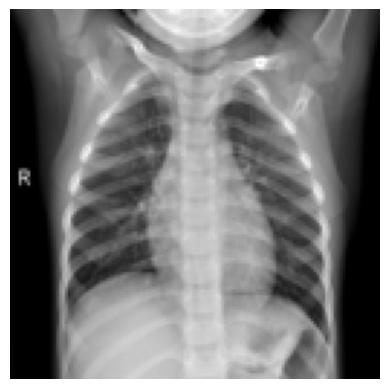

Tensor shape: torch.Size([1, 128, 128])
Pixel range: 0.0 0.9137254953384399


In [10]:

from PIL import Image
from torchvision import transforms

train_dir = os.path.join(data_dir, "train")
normal_dir = os.path.join(train_dir, "NORMAL")

image_name = next(
    f for f in os.listdir(normal_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
)
image_path = os.path.join(normal_dir, image_name)

img = Image.open(image_path).convert("L")

transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

x = transform(img)

plt.imshow(x.squeeze(0), cmap="gray")
plt.axis("off")
plt.show()

print("Tensor shape:", x.shape)
print("Pixel range:", x.min().item(), x.max().item())


In [11]:

from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader

train_dataset = ImageFolder(
    root=train_dir,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

print("Total training images:", len(train_dataset))
print("Classes:", train_dataset.classes)

images, labels = next(iter(train_loader))

print("Batch shape:", images.shape)


Total training images: 5216
Classes: ['NORMAL', 'PNEUMONIA']
Batch shape: torch.Size([32, 3, 128, 128])


In [12]:
#fix rgb to grayscale

transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

train_dataset.transform = transform

images, labels = next(iter(train_loader))

print("New batch shape:", images.shape)


New batch shape: torch.Size([32, 1, 128, 128])


In [16]:

class Encoder(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, 4, 2, 1),
            nn.ReLU(),

            nn.Conv2d(32, 64, 4, 2, 1),
            nn.ReLU(),

            nn.Conv2d(64, 128, 4, 2, 1),
            nn.ReLU(),

            nn.Conv2d(128, 256, 4, 2, 1),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(256 * 8 * 8, latent_dim)
        self.fc_logvar = nn.Linear(256 * 8 * 8, latent_dim)

    def forward(self, x):
        x = self.conv(x)
        x = x.flatten(start_dim=1)

        mu = self.fc_mu(x)
        logvar = self.fc_logvar(x)

        return mu, logvar


In [17]:

encoder = Encoder(latent_dim=64).to(device)

mu, logvar = encoder(images.to(device))

print("Mean shape:", mu.shape)
print("Log variance shape:", logvar.shape)


Mean shape: torch.Size([32, 64])
Log variance shape: torch.Size([32, 64])


In [19]:

class Decoder(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()

        self.fc = nn.Linear(latent_dim, 256 * 8 * 8)

        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, 2, 1),
            nn.ReLU(),

            nn.ConvTranspose2d(128, 64, 4, 2, 1),
            nn.ReLU(),

            nn.ConvTranspose2d(64, 32, 4, 2, 1),
            nn.ReLU(),

            nn.ConvTranspose2d(32, 1, 4, 2, 1),
            nn.Sigmoid()
        )

    def forward(self, z):
        x = self.fc(z)
        x = x.view(-1, 256, 8, 8)
        return self.deconv(x)


In [20]:

decoder = Decoder(latent_dim=64).to(device)

z = torch.randn(32, 64, device=device)

generated = decoder(z)

print("Generated shape:", generated.shape)


Generated shape: torch.Size([32, 1, 128, 128])


In [22]:

class VAE(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, x):
        mu, logvar = self.encoder(x)

        std = torch.exp(logvar / 2)
        noise = torch.randn_like(std)
        z = mu + std * noise

        reconstruction = self.decoder(z)

        return reconstruction, mu, logvar


vae = VAE(encoder, decoder).to(device)


In [23]:

x = images.to(device)

reconstruction, mu, logvar = vae(x)

print("Original:", x.shape)
print("Reconstructed:", reconstruction.shape)
print("Latent:", mu.shape)


Original: torch.Size([32, 1, 128, 128])
Reconstructed: torch.Size([32, 1, 128, 128])
Latent: torch.Size([32, 64])


In [24]:

import torch.nn.functional as F

def vae_loss(reconstruction, x, mu, logvar):
    recon_loss = F.mse_loss(
        reconstruction, x, reduction="sum"
    ) / x.size(0)

    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    ) / x.size(0)

    total_loss = recon_loss + kl_loss

    return total_loss, recon_loss, kl_loss


In [25]:

reconstruction, mu, logvar = vae(x)

loss, recon_loss, kl_loss = vae_loss(
    reconstruction, x, mu, logvar
)

print("Total loss:", loss.item())
print("Reconstruction loss:", recon_loss.item())
print("KL loss:", kl_loss.item())


Total loss: 978.031005859375
Reconstruction loss: 978.0254516601562
KL loss: 0.005566307343542576


In [26]:
optimizer = optim.Adam(vae.parameters(), lr=0.001)

epochs = 5
train_losses = []
recon_losses = []
kl_losses = []

for epoch in range(epochs):
    vae.train()

    total = 0
    total_recon = 0
    total_kl = 0

    for images, _ in train_loader:
        images = images.to(device)
        reconstruction, mu, logvar = vae(images)
        loss, recon_loss, kl_loss = vae_loss(
            reconstruction, images, mu, logvar
        )
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total += loss.item()
        total_recon += recon_loss.item()
        total_kl += kl_loss.item()

    train_losses.append(total / len(train_loader))
    recon_losses.append(total_recon / len(train_loader))
    kl_losses.append(total_kl / len(train_loader))

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Loss: {train_losses[-1]:.2f} | "
        f"Recon: {recon_losses[-1]:.2f} | "
        f"KL: {kl_losses[-1]:.2f}"
    )


Epoch 1/5 | Loss: 340.12 | Recon: 315.89 | KL: 24.23
Epoch 2/5 | Loss: 175.13 | Recon: 142.17 | KL: 32.96
Epoch 3/5 | Loss: 145.68 | Recon: 111.94 | KL: 33.74
Epoch 4/5 | Loss: 131.91 | Recon: 99.01 | KL: 32.90
Epoch 5/5 | Loss: 124.20 | Recon: 91.51 | KL: 32.68


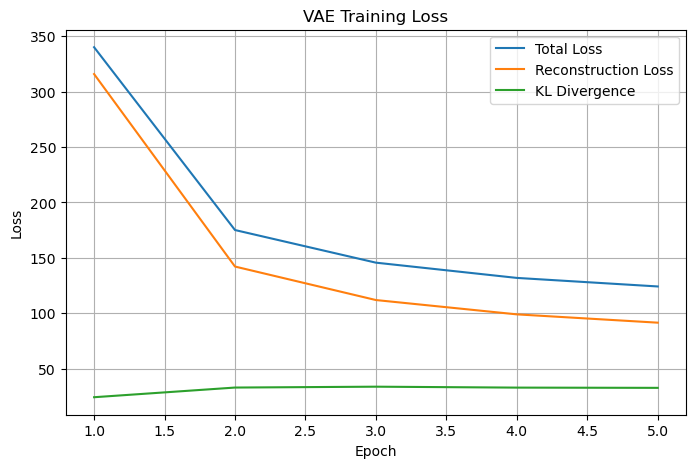

In [27]:

plt.figure(figsize=(8, 5))

plt.plot(range(1, 6), train_losses, label="Total Loss")
plt.plot(range(1, 6), recon_losses, label="Reconstruction Loss")
plt.plot(range(1, 6), kl_losses, label="KL Divergence")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE Training Loss")
plt.legend()
plt.grid(True)

plt.savefig("training_loss.png", dpi=300)
plt.show()


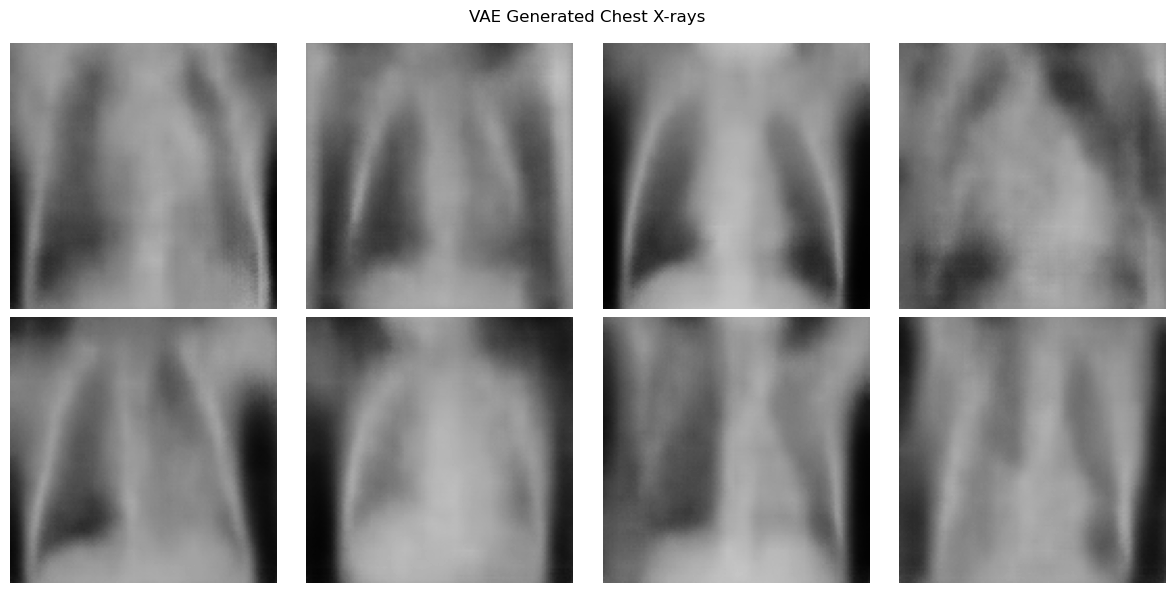

In [28]:
vae.eval()

with torch.no_grad():

    z = torch.randn(8, 64).to(device)

    generated_images = vae.decoder(z)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(generated_images[i, 0].cpu(), cmap="gray",
              vmin=0, vmax=1)
    ax.axis("off")

plt.suptitle("VAE Generated Chest X-rays")
plt.tight_layout()
plt.savefig("generated_xrays.png", dpi=300)
plt.show()


In [29]:

additional_epochs = 45

for group in optimizer.param_groups:
    group["lr"] = 0.0003

for epoch in range(additional_epochs):
    vae.train()

    total = 0
    total_recon = 0
    total_kl = 0

    for images, _ in train_loader:
        images = images.to(device)

        reconstruction, mu, logvar = vae(images)

        loss, recon_loss, kl_loss = vae_loss(
            reconstruction, images, mu, logvar
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total += loss.item()
        total_recon += recon_loss.item()
        total_kl += kl_loss.item()

    train_losses.append(total / len(train_loader))
    recon_losses.append(total_recon / len(train_loader))
    kl_losses.append(total_kl / len(train_loader))

    print(
        f"Epoch {len(train_losses)}/50 | "
        f"Loss: {train_losses[-1]:.2f} | "
        f"Recon: {recon_losses[-1]:.2f} | "
        f"KL: {kl_losses[-1]:.2f}"
    )

    if len(train_losses) % 10 == 0:
        torch.save({
            "model": vae.state_dict(),
            "optimizer": optimizer.state_dict(),
            "epoch": len(train_losses),
            "train_losses": train_losses,
            "recon_losses": recon_losses,
            "kl_losses": kl_losses
        }, f"vae_epoch_{len(train_losses)}.pth")


Epoch 6/50 | Loss: 116.62 | Recon: 84.11 | KL: 32.51
Epoch 7/50 | Loss: 114.36 | Recon: 81.86 | KL: 32.50
Epoch 8/50 | Loss: 113.04 | Recon: 80.57 | KL: 32.48
Epoch 9/50 | Loss: 111.95 | Recon: 79.33 | KL: 32.62
Epoch 10/50 | Loss: 111.04 | Recon: 78.46 | KL: 32.58
Epoch 11/50 | Loss: 110.33 | Recon: 77.68 | KL: 32.65
Epoch 12/50 | Loss: 109.31 | Recon: 76.74 | KL: 32.57
Epoch 13/50 | Loss: 108.55 | Recon: 75.97 | KL: 32.58
Epoch 14/50 | Loss: 107.88 | Recon: 75.31 | KL: 32.57
Epoch 15/50 | Loss: 107.31 | Recon: 74.65 | KL: 32.66
Epoch 16/50 | Loss: 106.90 | Recon: 74.22 | KL: 32.68
Epoch 17/50 | Loss: 106.02 | Recon: 73.54 | KL: 32.49
Epoch 18/50 | Loss: 105.66 | Recon: 73.02 | KL: 32.64
Epoch 19/50 | Loss: 105.39 | Recon: 72.80 | KL: 32.59
Epoch 20/50 | Loss: 104.86 | Recon: 72.22 | KL: 32.64
Epoch 21/50 | Loss: 104.22 | Recon: 71.67 | KL: 32.55
Epoch 22/50 | Loss: 104.02 | Recon: 71.30 | KL: 32.72
Epoch 23/50 | Loss: 103.44 | Recon: 70.81 | KL: 32.62
Epoch 24/50 | Loss: 103.32 | Rec

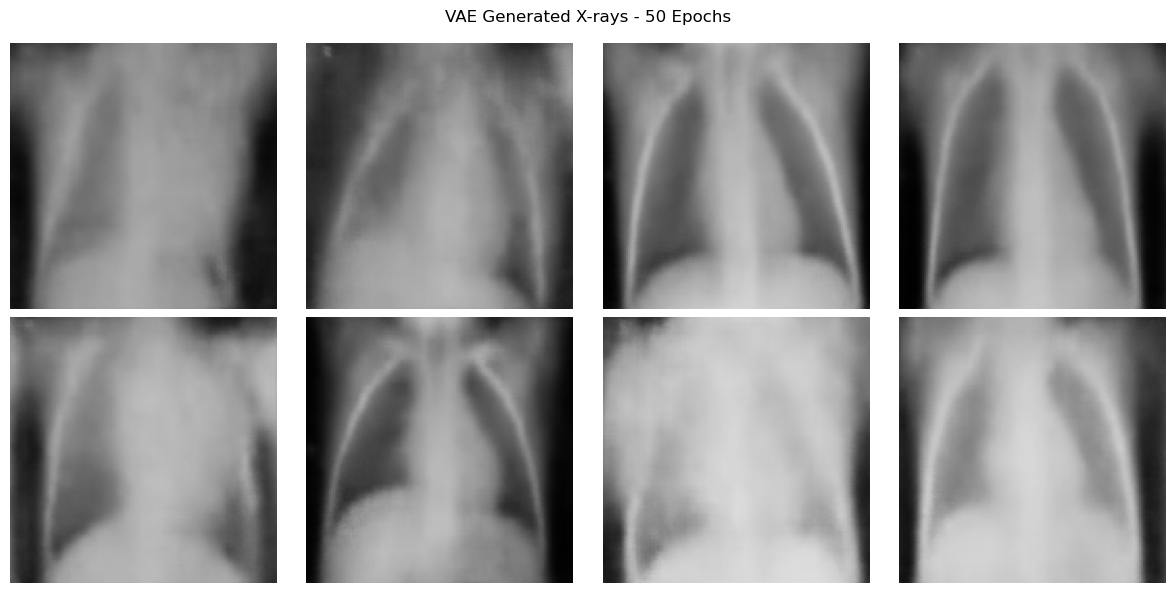

In [30]:

vae.eval()

with torch.no_grad():
    z = torch.randn(8, 64, device=device)
    generated_images = vae.decoder(z)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(
        generated_images[i, 0].cpu(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    ax.axis("off")

plt.suptitle("VAE Generated X-rays - 50 Epochs")
plt.tight_layout()
plt.savefig("generated_xrays_50.png", dpi=300)
plt.show()


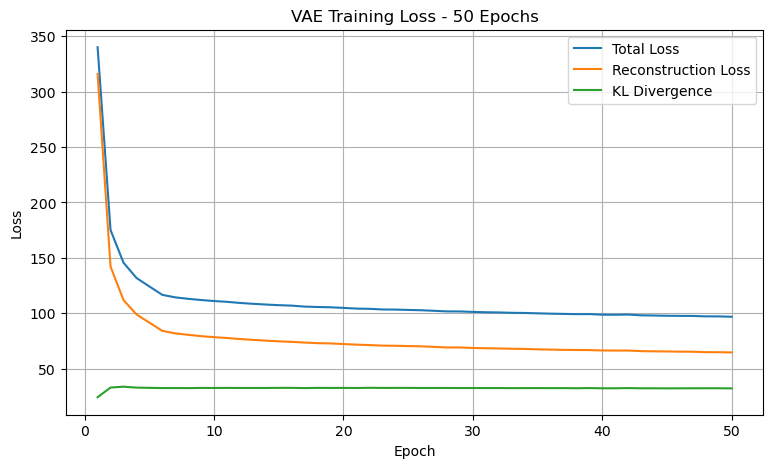

In [31]:

plt.figure(figsize=(9, 5))

epochs_range = range(1, len(train_losses) + 1)

plt.plot(epochs_range, train_losses, label="Total Loss")
plt.plot(epochs_range, recon_losses, label="Reconstruction Loss")
plt.plot(epochs_range, kl_losses, label="KL Divergence")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE Training Loss - 50 Epochs")
plt.legend()
plt.grid(True)

plt.savefig("training_loss_50.png", dpi=300)
plt.show()


In [32]:

%pip install pytorch-ignite scipy


Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 371.8/371.8 kB 18.2 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [33]:

import ignite
from ignite.engine import Engine
from ignite.metrics import FID, InceptionScore

print("Ignite version:", ignite.__version__)
print("FID and Inception Score imported successfully!")


Ignite version: 0.5.5
FID and Inception Score imported successfully!


In [34]:
test_dir = os.path.join(data_dir, "test")

test_dataset = ImageFolder(
    root=test_dir,
    transform=transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

real_images, labels = next(iter(test_loader))

print("Total test images:", len(test_dataset))
print("Real image batch shape:", real_images.shape)


Total test images: 624
Real image batch shape: torch.Size([16, 1, 128, 128])


In [35]:

from PIL import Image

def prepare_for_inception(batch):
    result = []

    for img in batch.detach().cpu():
        pil_img = transforms.ToPILImage()(img)

        pil_img = pil_img.resize(
            (299, 299), Image.Resampling.BILINEAR
        )

        pil_img = pil_img.convert("RGB")

        result.append(transforms.ToTensor()(pil_img))

    return torch.stack(result)

prepared = prepare_for_inception(real_images)
print("Original:", real_images.shape)
print("Prepared:", prepared.shape)


Original: torch.Size([16, 1, 128, 128])
Prepared: torch.Size([16, 3, 299, 299])


In [36]:
vae.eval()

def evaluation_step(engine, batch):
    real_images, _ = batch

    with torch.no_grad():
        batch_size = real_images.size(0)
        z = torch.randn(batch_size, 64, device=device)
        fake_images = vae.decoder(z)

        fake = prepare_for_inception(fake_images)
        real = prepare_for_inception(real_images)

    return fake, real

evaluator = Engine(evaluation_step)

fid_metric = FID(device=device)

is_metric = InceptionScore(
    device=device,
    output_transform=lambda output: output[0]
)

fid_metric.attach(evaluator, "fid")
is_metric.attach(evaluator, "is")

print("Evaluation engine ready!")


Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /home/gag009/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth
100%|██████████| 104M/104M [00:00<00:00, 246MB/s] 


Evaluation engine ready!


In [37]:

evaluator.run(test_loader)

metrics = evaluator.state.metrics

print("FID Score:", metrics["fid"])
print("Inception Score:", metrics["is"])


FID Score: 0.1731116730728316
Inception Score: 1.8838275300655818


In [38]:

with open("evaluation_results.txt", "w") as f:
    f.write("Chest X-ray VAE - Homework 1\n")
    f.write("Training epochs: 50\n")
    f.write("Latent dimensions: 64\n")
    f.write("Image resolution: 128x128\n")
    f.write("Test images: 624\n")
    f.write("FID (Ignite default, 1000 logits): "
            f"{metrics['fid']:.4f}\n")
    f.write(f"Inception Score: {metrics['is']:.4f}\n")

print("Evaluation results saved!")


Evaluation results saved!
